# Climate finance and forest-restoration potential

## Purpose and scope

This deep dive follows two separate calculations. The first distributes the hypothetical 2% GCW allocation across study entities and economic groups. The second reconstructs forest-restoration costs and supply from the public cell-level Busch inputs.

Busch et al.'s country-level source data are supplied in Stata's `.dta` file format. The restoration calculation is run for every country dataset in the archive before any link to FRA losses or the study entities. A later ISO3 join attaches positive FRA-loss targets to those completed country calculations. The 2% allocation is not observed finance or an estimated funding need, and the restoration scenario does not directly price protection of existing forests.

## Load the allocation, all-country restoration outputs and the later target join

The country-cost files describe every country dataset processed from the Busch archive. The separate coverage file contains only study entities with positive FRA loss and records whether an ISO3-matched country calculation is available. A country without a positive-loss target remains in the all-country cost files; it is simply absent from that target-coverage table.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = ROOT / 'data' / 'derived' / 'validation'
BUSCH_DIR = DATA / 'busch_reconstruction'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: C:\Users\aurel\Desktop\M2\Stage ecoseas-csm\CSM\BNC2 paper\repo


## 2. Examine how the 2% GCW scenario is distributed

The allocation is proportional to the annual GCW value of each eligible study unit, then summarized by economic group. Compare both the total assigned to a group and its share of the global scenario; the median per-unit value describes a different aspect of the distribution.

In [2]:
allocation = pd.read_csv(TABLES / 'Table4_our_2pct_gcw_allocation.csv')
assumptions = pd.read_csv(TABLES / 'Supplementary_deforestation_scenarios.csv')
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')

# Reconstruct the stipulated allocation from annual GCW and compare group sums with Table 4.
allocation_rate = 0.02
gcw = pd.to_numeric(accounts['gcw_usd2015_yr_mean'], errors='coerce')
exclude = accounts['exclude_from_country_sum'].fillna(False).astype(bool)
eligible = gcw.notna() & ~exclude
accounts.loc[eligible, 'reconstructed_allocation_usd2015_yr'] = allocation_rate * gcw.loc[eligible]
reconstructed = accounts.loc[eligible].groupby('groups', dropna=False)['reconstructed_allocation_usd2015_yr'].sum().div(1e9).rename('reconstructed_billion_usd2015').reset_index()
comparison = allocation.merge(reconstructed, left_on='group', right_on='groups', how='outer')
comparison['difference_billion_usd2015'] = comparison['reconstructed_billion_usd2015'] - comparison['annual_allocation_billion_usd2015']
display(comparison)
display(assumptions.loc[assumptions['metric'].astype(str).str.contains('rate|allocation|discount', case=False, na=False)])


C:\Users\aurel\AppData\Local\Temp\ipykernel_21788\1590006676.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  accounts.loc[eligible, 'reconstructed_allocation_usd2015_yr'] = allocation_rate * gcw.loc[eligible]


,group,units,annual_allocation_billion_usd2015,share_of_total_pct,median_allocation_per_unit_million_usd2015,groups,reconstructed_billion_usd2015,difference_billion_usd2015
0,Developed economies,62,72.239007,43.720574,113.724556,Developed economies,72.239007,8.795382e-10
1,Developing economies,80,68.601312,41.518964,156.314013,Developing economies,68.601312,-7.365813e-09
2,LDCs,37,21.089087,12.763561,185.188891,LDCs,21.089087,-3.881979e-10
3,SIDS,57,3.299455,1.996900,1.259196,SIDS,3.299455,-3.763221e-10
4,Total,236,165.228860,100.000000,NaN,NaN,NaN,NaN
5,Unclassified,0,0.000000,0.000000,NaN,NaN,NaN,NaN


,metric,value,unit,assumption_or_formula,discount_rate,our_allocation_rate
4,Perpetuity value of annual lost GCW at 2% disc...,0.933854,trillion US$2015,Annual lost GCW value / 0.02; perpetual consta...,0.02,NaN


### Visual summary: annual allocation by economic group

The bars show the hypothetical annual amount assigned under the same 2% rule. They do not show payments made, pledged finance or a recommended contribution.

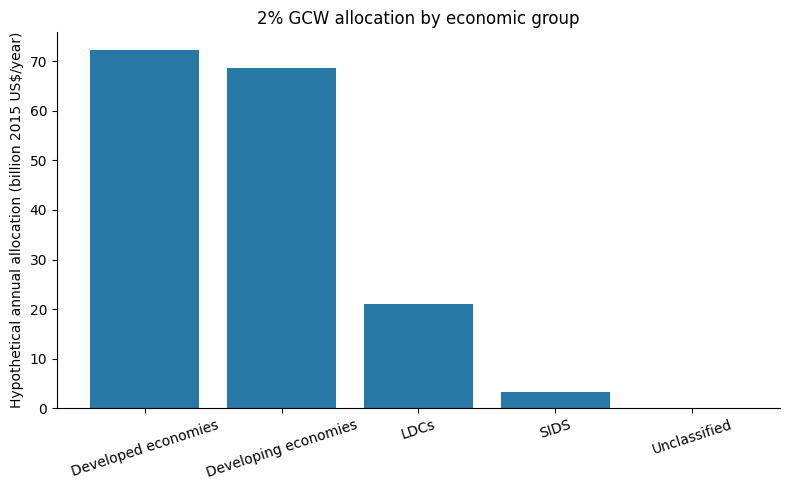

In [3]:
allocation_plot = allocation.loc[allocation["group"].ne("Total")].copy()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(allocation_plot["group"], allocation_plot["annual_allocation_billion_usd2015"], color="#2878A5")
ax.set_ylabel("Hypothetical annual allocation (billion 2015 US$/year)")
ax.set_title("2% GCW allocation by economic group")
ax.tick_params(axis="x", rotation=18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Country and territory ranking

For each eligible study entity $i$, the annual scenario amount is $A_i^{2\%}=0.02\,GCW_i$. The chart ranks all entities with a reported GCW from the largest allocation to the smallest. An entity with a missing GCW is left out rather than assigned zero; an actual zero GCW remains at the bottom of the ranking. Colours distinguish the economic groups. A symmetric logarithmic axis keeps the full range visible, including zero and very small amounts.


,Country or territory,Economic group,GCW annual mean (2015 US$/year),Hypothetical 2% allocation (2015 US$/year)
0,Russian Federation (RUS),Developed economies,"1,195,472,314,000","23,909,446,280"
1,Brazil (BRA),Developing economies,"938,374,837,900","18,767,496,758"
2,United States of America (USA),Developed economies,"819,432,382,800","16,388,647,656"
3,"China (incl. Taiwan, Hong Kong SAR and Macao S...",Developing economies,"610,133,425,800","12,202,668,516"
4,Canada (CAN),Developed economies,"609,367,250,700","12,187,345,014"
5,Australia (AUS),Developed economies,"363,387,960,200","7,267,759,204"
6,Democratic Republic of the Congo (COD),LDCs,"266,848,852,300","5,336,977,046"
7,Indonesia (IDN),Developing economies,"183,989,321,300","3,679,786,426"
8,India (IND),Developing economies,"152,516,130,700","3,050,322,614"
9,Mexico (MEX),Developing economies,"152,433,564,600","3,048,671,292"


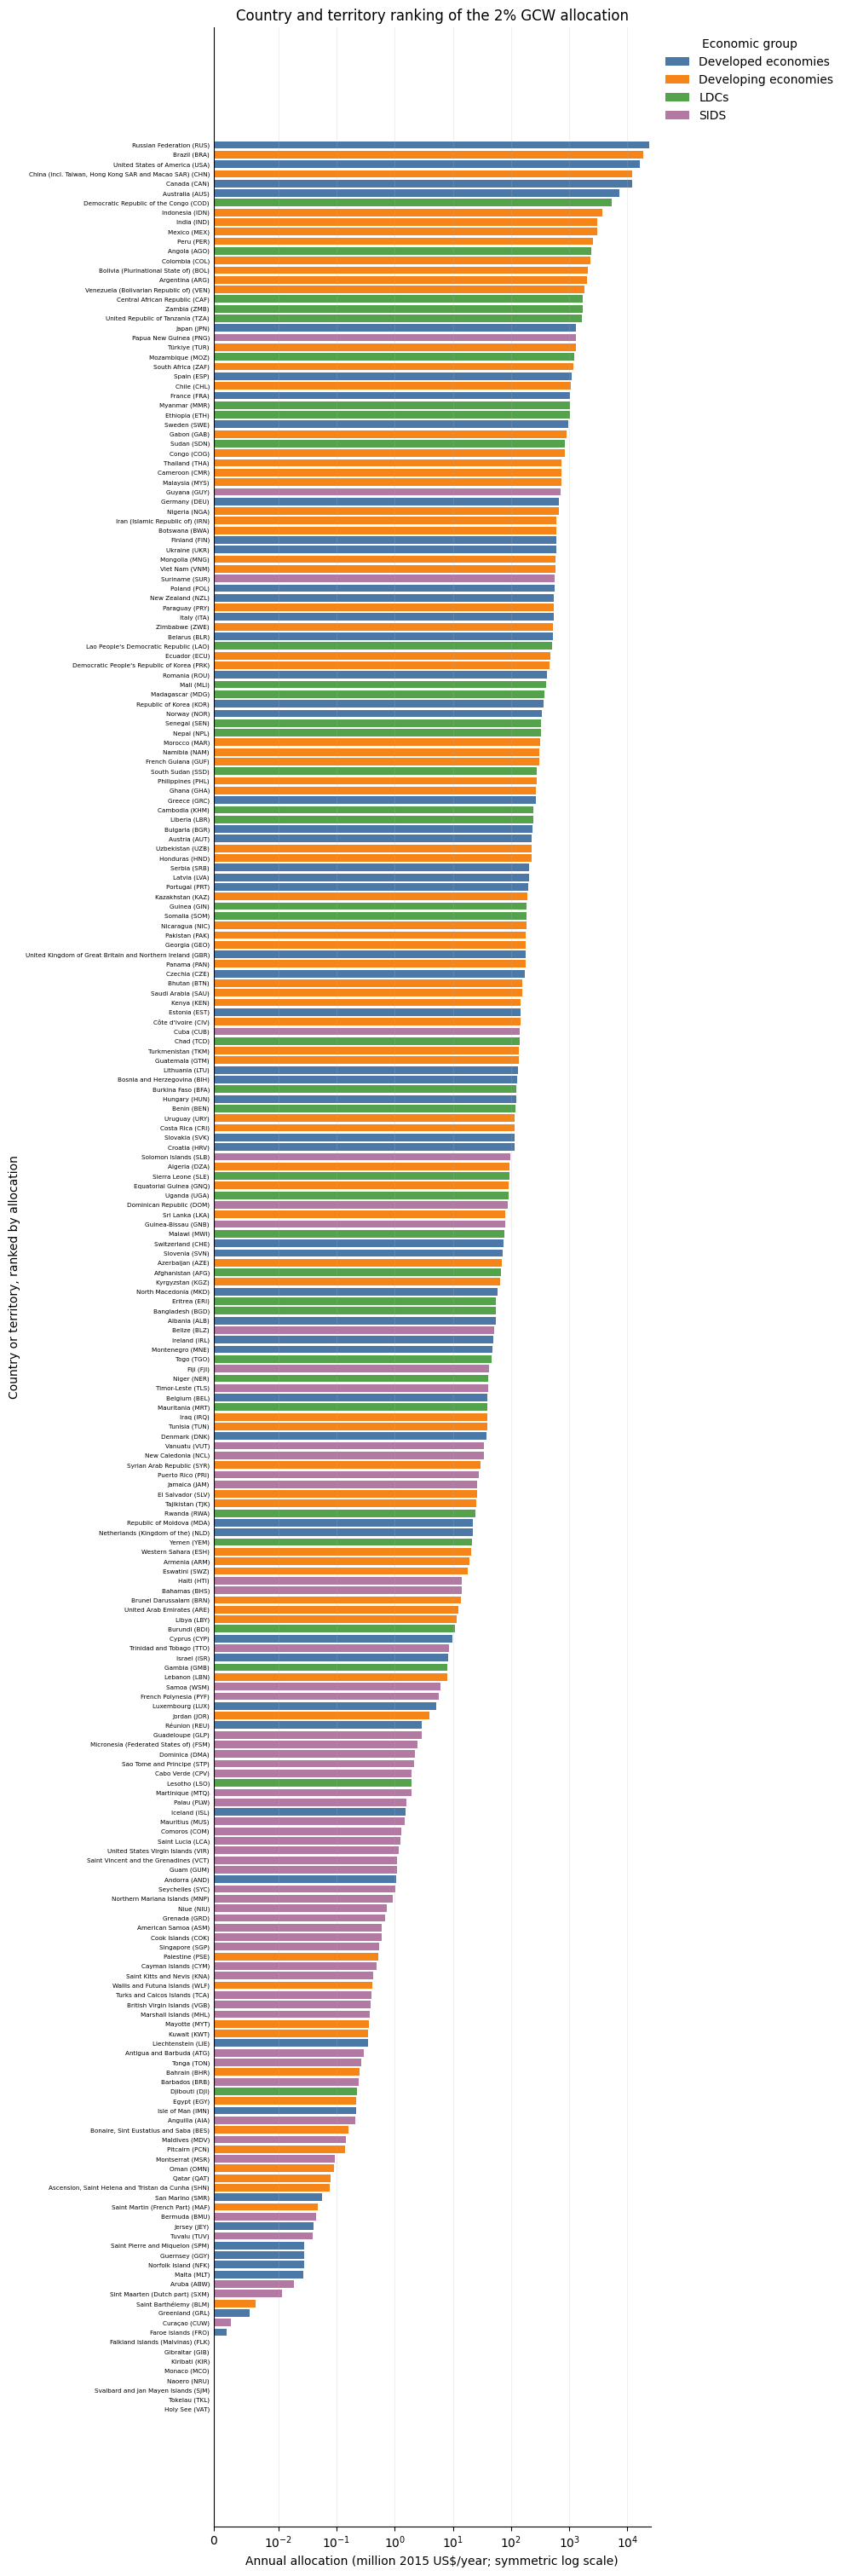

Ranked 236 eligible entities; 8 have zero allocation. Entities without a reported GCW are omitted, not treated as zero.


In [4]:
from matplotlib.patches import Patch

country_allocation = accounts.loc[eligible, [
    'UNIT_CODE', 'ISO3', 'name', 'groups', 'gcw_usd2015_yr_mean',
    'reconstructed_allocation_usd2015_yr',
]].copy()
country_allocation = country_allocation.rename(columns={
    'groups': 'economic_group',
    'reconstructed_allocation_usd2015_yr': 'allocation_usd2015_yr',
})
country_allocation['economic_group'] = country_allocation['economic_group'].fillna('Unclassified')
country_allocation['allocation_million_usd2015_yr'] = country_allocation['allocation_usd2015_yr'] / 1e6
country_allocation['display_name'] = country_allocation['name'] + ' (' + country_allocation['ISO3'] + ')'
country_allocation = country_allocation.sort_values(
    'allocation_usd2015_yr', ascending=False, kind='stable'
).reset_index(drop=True)

# Show the leading entries, while the ranked chart below includes every eligible entity.
allocation_top10 = country_allocation[[
    'display_name', 'economic_group', 'gcw_usd2015_yr_mean', 'allocation_usd2015_yr'
]].head(10).rename(columns={
    'display_name': 'Country or territory',
    'economic_group': 'Economic group',
    'gcw_usd2015_yr_mean': 'GCW annual mean (2015 US$/year)',
    'allocation_usd2015_yr': 'Hypothetical 2% allocation (2015 US$/year)',
})
for column in ('GCW annual mean (2015 US$/year)', 'Hypothetical 2% allocation (2015 US$/year)'):
    allocation_top10[column] = allocation_top10[column].map(lambda value: f'{value:,.0f}')
display(allocation_top10)

allocation_group_colors = {
    'Developed economies': '#4C78A8',
    'Developing economies': '#F58518',
    'LDCs': '#54A24B',
    'SIDS': '#B279A2',
    'Unclassified': '#9D9D9D',
}
rank_colors = country_allocation['economic_group'].map(allocation_group_colors).fillna('#9D9D9D')
fig, ax = plt.subplots(figsize=(12, max(20, 0.12 * len(country_allocation) + 2)))
ax.barh(
    country_allocation['display_name'],
    country_allocation['allocation_million_usd2015_yr'],
    color=rank_colors,
    height=0.78,
)
ax.invert_yaxis()
ax.set_xscale('symlog', linthresh=0.01, linscale=1)
ax.set_xlabel('Annual allocation (million 2015 US$/year; symmetric log scale)')
ax.set_ylabel('Country or territory, ranked by allocation')
ax.set_title('Country and territory ranking of the 2% GCW allocation')
ax.tick_params(axis='y', labelsize=5.2, length=0)
ax.grid(axis='x', which='both', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)
allocation_groups_present = [
    group for group in allocation_group_colors if group in set(country_allocation['economic_group'])
]
ax.legend(
    handles=[Patch(facecolor=allocation_group_colors[group], label=group) for group in allocation_groups_present],
    title='Economic group', loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False,
)
fig.tight_layout(rect=[0, 0, 0.84, 1])
plt.show()
print(
    f'Ranked {len(country_allocation)} eligible entities; '
    f'{int(country_allocation["allocation_usd2015_yr"].eq(0).sum())} have zero allocation. '
    'Entities without a reported GCW are omitted, not treated as zero.'
)


### Geographic distribution of the 2% allocation

This choropleth uses the repository’s fixed land-boundary layer at `web/public/data/land.geojson` and joins the allocation to each polygon by ISO3 code. The colours show positive annual allocations on a logarithmic scale; white marks a reported zero allocation and light gray marks an entity without an eligible GCW value. The map layer contains polygons for all eligible entities in the ranking. This is the same hypothetical annual scenario shown above, not observed financing.


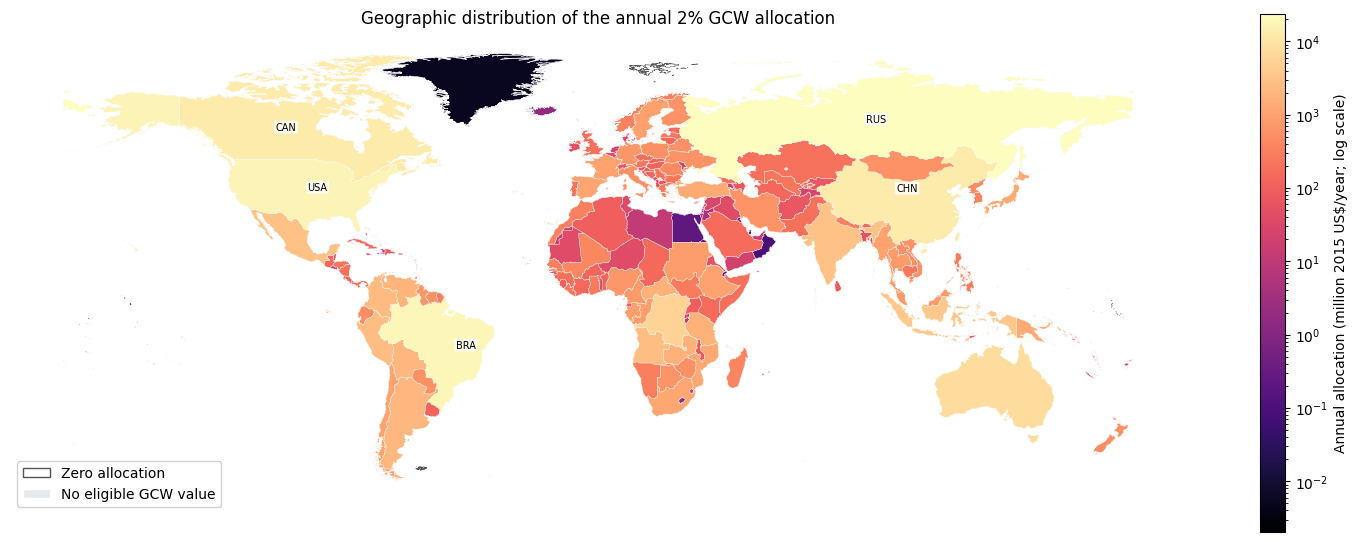

236 of 236 eligible entities match a polygon in the repository map layer.


In [5]:
import geopandas as gpd
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

land_path = ROOT / 'web' / 'public' / 'data' / 'land.geojson'
country_land = gpd.read_file(land_path)
allocation_map = country_land.merge(
    country_allocation[[
        'ISO3', 'name', 'economic_group', 'allocation_usd2015_yr',
        'allocation_million_usd2015_yr',
    ]],
    left_on='code', right_on='ISO3', how='left', validate='one_to_one',
)
positive_allocation_map = allocation_map.loc[
    allocation_map['allocation_million_usd2015_yr'].gt(0)
]
zero_allocation_map = allocation_map.loc[
    allocation_map['allocation_million_usd2015_yr'].eq(0)
]

fig, ax = plt.subplots(figsize=(15, 7.5))
country_land.plot(color='#E7EAED', edgecolor='white', linewidth=0.25, ax=ax)
positive_allocation_map.plot(
    column='allocation_million_usd2015_yr',
    cmap='magma',
    norm=LogNorm(
        vmin=positive_allocation_map['allocation_million_usd2015_yr'].min(),
        vmax=positive_allocation_map['allocation_million_usd2015_yr'].max(),
    ),
    linewidth=0.25,
    edgecolor='white',
    ax=ax,
    legend=True,
    legend_kwds={
        'label': 'Annual allocation (million 2015 US$/year; log scale)',
        'shrink': 0.72,
    },
)
zero_allocation_map.plot(color='white', edgecolor='#555555', linewidth=0.35, ax=ax)

# Label the five largest allocations using points inside the repository's land polygons.
for row in allocation_map.nlargest(5, 'allocation_usd2015_yr').itertuples(index=False):
    point = row.geometry.representative_point()
    ax.annotate(
        row.ISO3, (point.x, point.y), xytext=(4, 4), textcoords='offset points',
        fontsize=7, color='black',
        bbox={'boxstyle': 'round,pad=0.15', 'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'},
    )
ax.legend(
    handles=[
        Patch(facecolor='white', edgecolor='#555555', label='Zero allocation'),
        Patch(facecolor='#E7EAED', edgecolor='white', label='No eligible GCW value'),
    ],
    loc='lower left', frameon=True, framealpha=0.9,
)
ax.set_title('Geographic distribution of the annual 2% GCW allocation')
ax.set_axis_off()
fig.tight_layout()
plt.show()

mapped_entities = allocation_map.loc[allocation_map['ISO3'].notna(), 'ISO3'].nunique()
print(
    f'{mapped_entities} of {country_allocation["ISO3"].nunique()} eligible entities '
    'match a polygon in the repository map layer.'
)


## 3. Examine restoration supply and costs for every archive country

Country costs are calculated for every country dataset in the Busch archive, independently of FRA loss and study-table coverage. Use it to inspect all calculated country supplies and cost curves. The coverage table is created afterward: it joins only positive FRA-loss targets by ISO3 so that those targets can be compared with the previously calculated country-level supply. No published national curve is used to select or validate the calculation.

,measure,count
0,Country datasets in Busch archive,138
1,Country datasets processed,138
2,Study entities with positive FRA loss,100
3,Positive-loss entities with matched country data,69
4,Positive-loss entities without matched country...,31


,iso3,output_cells,selected_natural_regeneration_cells,selected_plantation_cells,available_discounted_tco2
12,BRA,8556934,1209728,7187550,3.798820e+10
18,CHN,6189576,2831541,3312437,1.827300e+10
74,MEX,1219912,789710,382780,6.844903e+09
54,IND,2447772,1460338,615756,5.080917e+09
24,COL,1096485,742820,342330,4.631660e+09
77,MMR,696217,180911,511726,4.218385e+09
115,THA,523025,14282,506642,3.831602e+09
53,IDN,1800315,1228775,519063,3.669808e+09
130,VEN,804648,230688,571584,3.022627e+09
21,COD,2325739,1341345,913423,2.831171e+09


,iso3,name,reported_loss_capacity_tco2_yr,target_discounted_30yr_tco2,available_discounted_tco2,status
0,BRA,Brazil,1.126536e+07,1.769475e+08,3.798820e+10,target_within_cell_supply
1,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",1.315226e+06,2.065854e+07,1.827300e+10,target_within_cell_supply
2,CAN,Canada,1.491670e+05,2.342999e+06,NaN,no_country_input_dta
3,AUS,Australia,2.175637e+06,3.417322e+07,NaN,no_country_input_dta
4,COD,Democratic Republic of the Congo,9.713073e+05,1.525654e+07,2.831171e+09,target_within_cell_supply
5,IDN,Indonesia,3.725915e+05,5.852378e+06,3.669808e+09,target_within_cell_supply
6,IND,India,2.218650e+06,3.484883e+07,5.080917e+09,target_within_cell_supply
7,MEX,Mexico,6.816678e+05,1.070711e+07,6.844903e+09,target_within_cell_supply
8,AGO,Angola,1.748833e+06,2.746931e+07,6.022370e+07,target_within_cell_supply
9,COL,Colombia,4.571140e+05,7.179992e+06,4.631660e+09,target_within_cell_supply


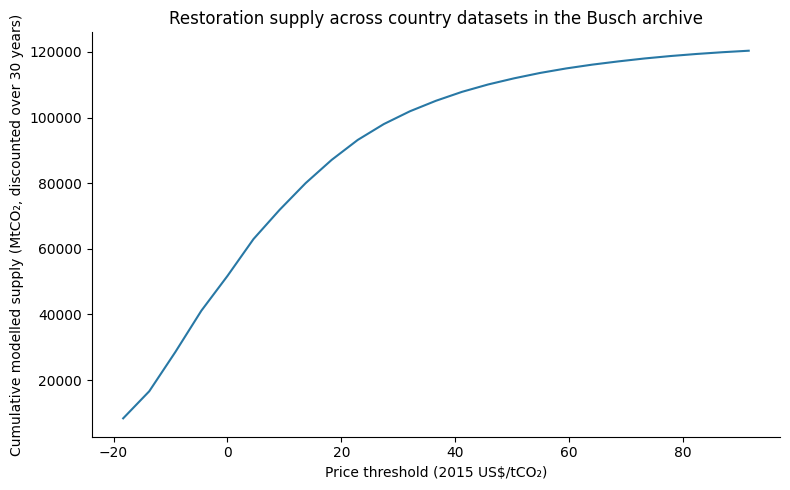

In [6]:
import json

BUSCH_DIR = DATA / "busch_reconstruction"
busch_prefix = "busch_all_dta"
busch_summary = json.loads((BUSCH_DIR / f"{busch_prefix}_summary.json").read_text(encoding="utf-8"))
all_country_costs = pd.read_csv(BUSCH_DIR / f"{busch_prefix}_country_finance.csv")
all_country_price_curves = pd.read_csv(BUSCH_DIR / f"{busch_prefix}_25_price_curves.csv")
all_country_effective_curves = pd.read_csv(BUSCH_DIR / f"{busch_prefix}_effective_cost_curves.csv")
positive_loss_coverage = pd.read_csv(BUSCH_DIR / f"{busch_prefix}_coverage.csv")

archive_scope = pd.DataFrame([
    {"measure": "Country datasets in Busch archive", "count": busch_summary["archive_country_dta_count"]},
    {"measure": "Country datasets processed", "count": busch_summary["processed_country_dta_count"]},
    {"measure": "Study entities with positive FRA loss", "count": busch_summary["positive_loss_entities"]},
    {"measure": "Positive-loss entities with matched country data", "count": busch_summary["positive_loss_entities_with_dta"]},
    {"measure": "Positive-loss entities without matched country data", "count": busch_summary["positive_loss_entities_without_dta"]},
])
display(archive_scope)

display(
    all_country_costs.sort_values("available_discounted_tco2", ascending=False)
    [["iso3", "output_cells", "selected_natural_regeneration_cells",
      "selected_plantation_cells", "available_discounted_tco2"]]
    .head(20)
)
coverage_preview = positive_loss_coverage[[
    'iso3', 'name', 'reported_loss_capacity_tco2_yr',
    'target_discounted_30yr_tco2', 'available_discounted_tco2', 'status',
]].head(20)
display(coverage_preview)

# Summing the country-level cumulative curves gives an archive-wide descriptive curve.
archive_price_curve = (
    all_country_price_curves.groupby("price_usd2015_per_tco2", as_index=False)
    ["cumulative_supply_discounted_tco2"].sum()
    .sort_values("price_usd2015_per_tco2")
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    archive_price_curve["price_usd2015_per_tco2"],
    archive_price_curve["cumulative_supply_discounted_tco2"] / 1e6,
    color="#2878A5",
)
ax.set_xlabel("Price threshold (2015 US$/tCO₂)")
ax.set_ylabel("Cumulative modelled supply (MtCO₂, discounted over 30 years)")
ax.set_title("Restoration supply across country datasets in the Busch archive")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Country-level supply, price and geography

The following views use the complete set of country-level calculations from the Busch dataset. Country names and broad regions are attached by ISO3 from the study account table. The price-curve panels show the six countries with the largest total modelled supply; this display rule does not filter the underlying country calculations. Positive-loss targets are compared separately, after the country calculations are complete.

In [7]:
# Add country labels and account classifications to the complete set of Busch country calculations.
country_metadata_source = pd.read_csv(DATA / 'accounts' / 'country_level_ncw_accounts.csv')
country_metadata = country_metadata_source.loc[:, ['iso3', 'name', 'continent', 'groups']].copy()
country_metadata['iso3'] = country_metadata['iso3'].astype('string').str.strip().str.upper()
country_metadata = country_metadata.drop_duplicates('iso3')

country_finance = all_country_costs.copy()
country_finance['iso3'] = country_finance['iso3'].astype('string').str.strip().str.upper()
country_finance = country_finance.merge(
    country_metadata,
    on='iso3',
    how='left',
    validate='one_to_one',
)
country_finance['selected_cells'] = (
    country_finance['selected_natural_regeneration_cells'].fillna(0)
    + country_finance['selected_plantation_cells'].fillna(0)
)
country_finance['natural_regeneration_share_pct'] = np.where(
    country_finance['selected_cells'].gt(0),
    100 * country_finance['selected_natural_regeneration_cells'] / country_finance['selected_cells'],
    np.nan,
)
country_finance['available_supply_mtco2'] = country_finance['available_discounted_tco2'] / 1e6

country_view_summary = pd.DataFrame({
    'measure': [
        'Country calculations from the Busch dataset',
        'Countries with positive modelled supply',
        'Countries matched to account metadata',
        'Countries with effective-cost curves',
    ],
    'count': [
        country_finance['iso3'].nunique(),
        int(country_finance['available_discounted_tco2'].gt(0).sum()),
        int(country_finance['name'].notna().sum()),
        int(all_country_effective_curves['iso3'].nunique()),
    ],
})
display(country_view_summary)

top_supply_countries = country_finance.nlargest(15, 'available_discounted_tco2')
display(top_supply_countries[[
    'iso3', 'name', 'continent', 'groups', 'output_cells',
    'selected_natural_regeneration_cells', 'selected_plantation_cells',
    'available_supply_mtco2', 'wood_fraction_w',
]])

,measure,count
0,Country calculations from the Busch dataset,138
1,Countries with positive modelled supply,106
2,Countries matched to account metadata,138
3,Countries with effective-cost curves,106


,iso3,name,continent,groups,output_cells,selected_natural_regeneration_cells,selected_plantation_cells,available_supply_mtco2,wood_fraction_w
12,BRA,Brazil,Americas,Developing economies,8556934,1209728,7187550,37988.199106,0.268
18,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Asia,Developing economies,6189576,2831541,3312437,18273.002912,0.355
74,MEX,Mexico,Americas,Developing economies,1219912,789710,382780,6844.902516,0.188
54,IND,India,Asia,Developing economies,2447772,1460338,615756,5080.916642,0.355
24,COL,Colombia,Americas,Developing economies,1096485,742820,342330,4631.659594,0.268
77,MMR,Myanmar,Asia,LDCs,696217,180911,511726,4218.385121,0.355
115,THA,Thailand,Asia,Developing economies,523025,14282,506642,3831.601837,0.355
53,IDN,Indonesia,Asia,Developing economies,1800315,1228775,519063,3669.807563,0.355
130,VEN,Venezuela (Bolivarian Republic of),Americas,Developing economies,804648,230688,571584,3022.626568,0.268
21,COD,Democratic Republic of the Congo,Africa,LDCs,2325739,1341345,913423,2831.171040,0.392


#### Countries with the largest modelled supply

The bar chart ranks the 15 countries in the Busch dataset with the largest calculated 30-year discounted supply. The horizontal scale is in million tonnes of CO₂.

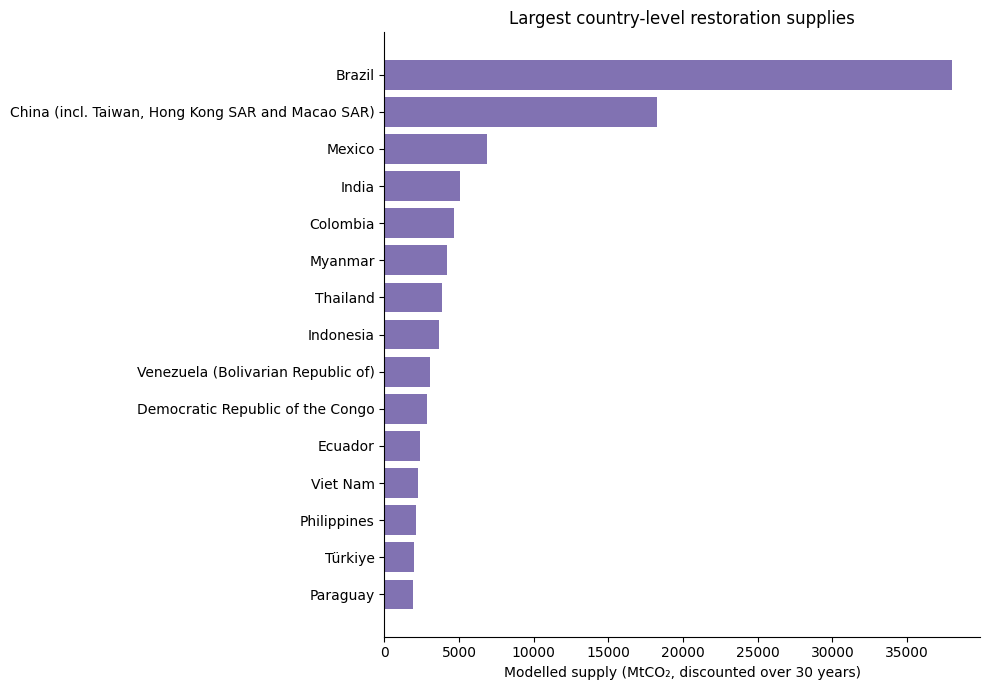

In [8]:
top_bar = top_supply_countries.sort_values('available_supply_mtco2')
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_bar['name'].fillna(top_bar['iso3']), top_bar['available_supply_mtco2'], color='#8172B2')
ax.set_xlabel('Modelled supply (MtCO₂, discounted over 30 years)')
ax.set_title('Largest country-level restoration supplies')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

#### Country-level price–supply curves

Each panel shows cumulative modelled supply available below successive price thresholds for one country in the Busch dataset. The six countries are selected by total available supply for display; each panel has its own vertical scale. Country names and ISO3 codes identify the panels; the long source label for CHN is shortened to “China” for readability.

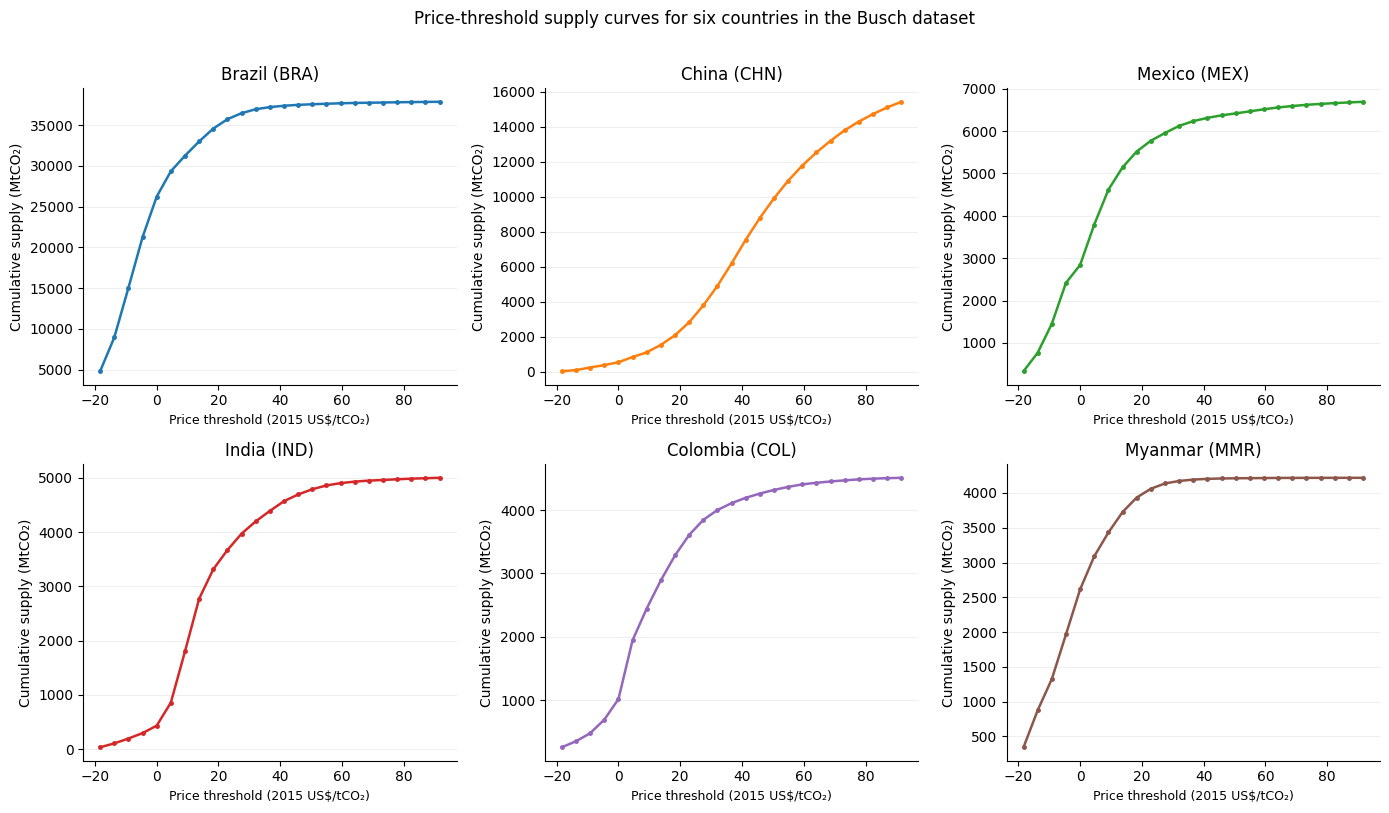

In [9]:
curve_examples = country_finance.nlargest(6, 'available_discounted_tco2')[['iso3', 'name']]
curve_colors = {iso3: plt.get_cmap('tab10')(i) for i, iso3 in enumerate(curve_examples['iso3'])}
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
for ax, row in zip(axes.flat, curve_examples.itertuples(index=False)):
    data = all_country_price_curves.loc[all_country_price_curves['iso3'].eq(row.iso3)].sort_values('price_usd2015_per_tco2')
    ax.plot(
        data['price_usd2015_per_tco2'],
        data['cumulative_supply_discounted_tco2'] / 1e6,
        color=curve_colors[row.iso3],
        marker='o',
        markersize=2.5,
        linewidth=1.8,
    )
    display_name = 'China' if row.iso3 == 'CHN' else row.name
    ax.set_title(f'{display_name} ({row.iso3})')
    ax.set_xlabel('Price threshold (2015 US$/tCO₂)', fontsize=9)
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_ylabel('Cumulative supply (MtCO₂)')
    ax.grid(axis='y', alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.flat[len(curve_examples):]:
    ax.set_visible(False)
fig.suptitle('Price-threshold supply curves for six countries in the Busch dataset', y=1.01)
fig.tight_layout()
plt.show()

#### Marginal effective-cost curves by country

These panels plot the cumulative discounted supply against the marginal effective cost in the reconstructed cell-level results. They use the available effective-cost curves; the source-country published curves are not used in this analysis.

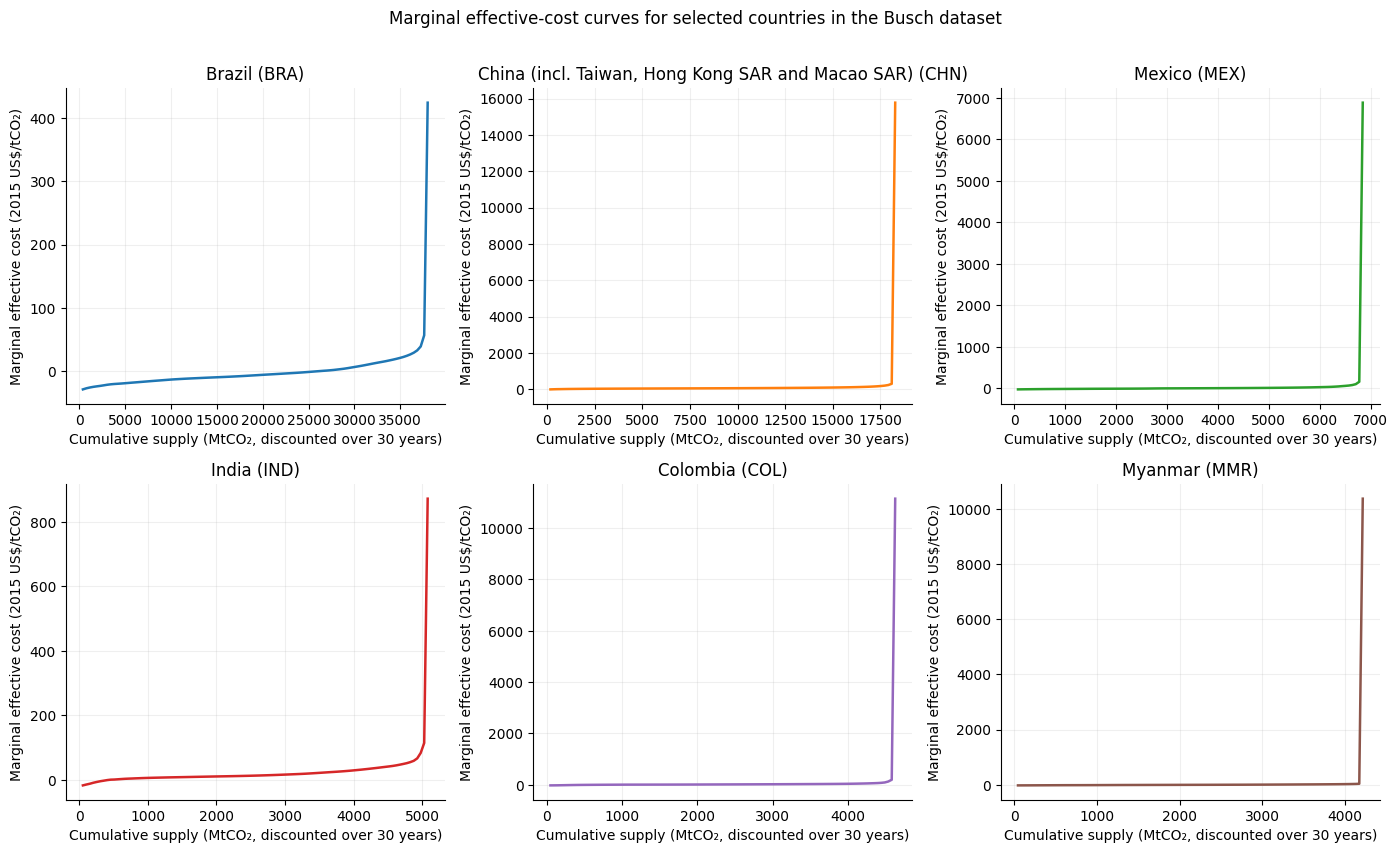

In [10]:
effective_examples = curve_examples.loc[curve_examples['iso3'].isin(all_country_effective_curves['iso3'].unique())]
nrows = int(np.ceil(len(effective_examples) / 3))
fig, axes = plt.subplots(nrows, 3, figsize=(14, 4.2 * nrows), squeeze=False)
for ax, row in zip(axes.flat, effective_examples.itertuples(index=False)):
    data = all_country_effective_curves.loc[all_country_effective_curves['iso3'].eq(row.iso3)].sort_values('supply_percentile')
    ax.plot(
        data['cumulative_discounted_tco2'] / 1e6,
        data['marginal_effective_cost_usd2015_per_tco2'],
        color=curve_colors.get(row.iso3, '#E07A5F'),
        linewidth=1.8,
    )
    ax.set_title(f'{row.name} ({row.iso3})')
    ax.set_xlabel('Cumulative supply (MtCO₂, discounted over 30 years)')
    ax.set_ylabel('Marginal effective cost (2015 US$/tCO₂)')
    ax.grid(alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.flat[len(effective_examples):]:
    ax.set_visible(False)
fig.suptitle('Marginal effective-cost curves for selected countries in the Busch dataset', y=1.01)
fig.tight_layout()
plt.show()

#### Supply, modelled cell count and restoration method mix

Each point represents a country in the Busch dataset with positive modelled supply. Both axes use logarithmic scales because country-level cell counts and supplies span different orders of magnitude. Colour indicates the share of selected cells assigned to natural regeneration.

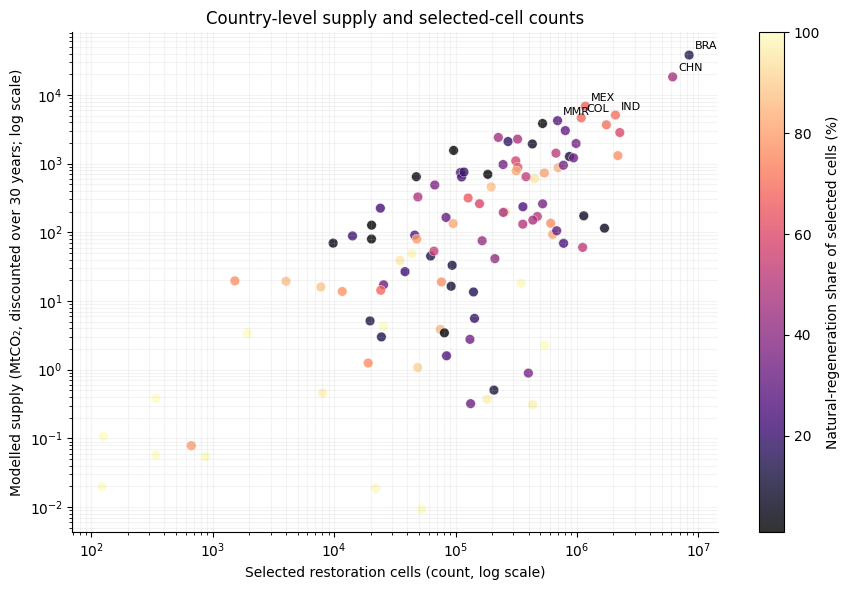

In [11]:
scatter_data = country_finance.loc[
    country_finance['available_discounted_tco2'].gt(0)
    & country_finance['selected_cells'].gt(0)
].copy()
fig, ax = plt.subplots(figsize=(9, 6))
points = ax.scatter(
    scatter_data['selected_cells'],
    scatter_data['available_supply_mtco2'],
    c=scatter_data['natural_regeneration_share_pct'],
    cmap='magma',
    s=48,
    alpha=0.8,
    edgecolors='white',
    linewidths=0.35,
)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Selected restoration cells (count, log scale)')
ax.set_ylabel('Modelled supply (MtCO₂, discounted over 30 years; log scale)')
ax.set_title('Country-level supply and selected-cell counts')
fig.colorbar(points, ax=ax, label='Natural-regeneration share of selected cells (%)')
for row in scatter_data.nlargest(6, 'available_discounted_tco2').itertuples(index=False):
    ax.annotate(row.iso3, (row.selected_cells, row.available_supply_mtco2), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.grid(which='both', alpha=0.15)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

#### Supply distributions by geographic and economic profile

The box plots compare positive country-level supply values by the region and economic-group labels in the study account table. The vertical axis is logarithmic; points beyond the whiskers are hidden for legibility, while all positive observations remain represented in the underlying groups.

C:\Users\aurel\AppData\Local\Temp\ipykernel_21788\222160768.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = ax.boxplot(values, labels=labels, showfliers=False, patch_artist=True,
C:\Users\aurel\AppData\Local\Temp\ipykernel_21788\222160768.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = ax.boxplot(values, labels=labels, showfliers=False, patch_artist=True,


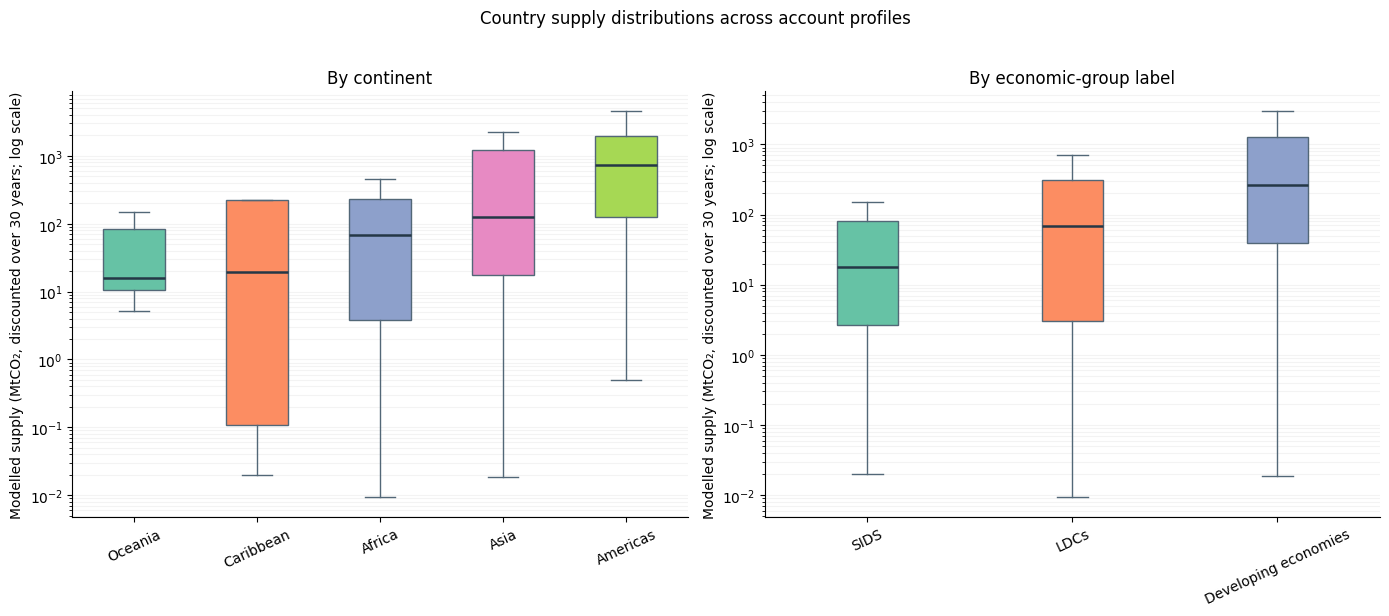

In [12]:
profile_data = country_finance.loc[country_finance['available_supply_mtco2'].gt(0)].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, column, title in [
    (axes[0], 'continent', 'By continent'),
    (axes[1], 'groups', 'By economic-group label'),
]:
    profile_data[column] = profile_data[column].fillna('No account label')
    grouped = profile_data.groupby(column)['available_supply_mtco2']
    labels = sorted(grouped.groups, key=lambda label: grouped.get_group(label).median())
    values = [grouped.get_group(label).to_numpy() for label in labels]
    boxplot = ax.boxplot(values, labels=labels, showfliers=False, patch_artist=True,
                         boxprops={'facecolor': 'white', 'edgecolor': '#526777'},
                         medianprops={'color': '#243746', 'linewidth': 1.8},
                         whiskerprops={'color': '#526777'}, capprops={'color': '#526777'})
    palette = plt.get_cmap('Set2')
    for index, box in enumerate(boxplot['boxes']):
        box.set_facecolor(palette(index % palette.N))
    ax.set_yscale('log')
    ax.set_title(title)
    ax.set_ylabel('Modelled supply (MtCO₂, discounted over 30 years; log scale)')
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', which='both', alpha=0.15)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Country supply distributions across account profiles', y=1.02)
fig.tight_layout()
plt.show()

#### Positive-loss targets compared with modelled country supply

This bubble plot shows positive FRA-loss entities with a matching country-level calculation from the Busch dataset and positive modelled supply. Both axes show discounted 30-year quantities in MtCO₂. The diagonal marks equal target and supply; bubble size represents the number of priced cells, and colour distinguishes whether the target is within or above modelled supply. Countries with zero modelled supply are listed separately immediately before the plot.

,iso3,name,reported_loss_capacity_tco2_yr,target_discounted_30yr_tco2,available_discounted_tco2,status
20,SDN,Sudan,904497.793300,1.420715e+07,0.0,target_outside_cell_supply
62,BFA,Burkina Faso,438236.050200,6.883472e+06,0.0,target_outside_cell_supply
35,MLI,Mali,394313.073200,6.193564e+06,0.0,target_outside_cell_supply
80,NER,Niger,68248.471600,1.071994e+06,0.0,target_outside_cell_supply
83,IRQ,Iraq,33171.861600,5.210379e+05,0.0,target_outside_cell_supply
41,NAM,Namibia,11032.132780,1.732842e+05,0.0,target_outside_cell_supply
92,SWZ,Eswatini,5571.168489,8.750760e+04,0.0,target_outside_cell_supply


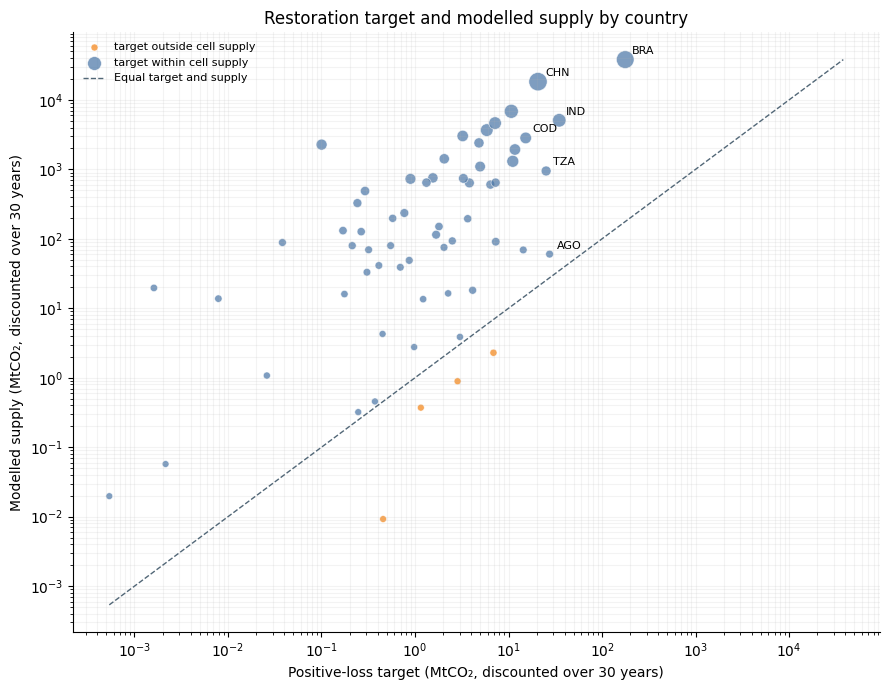

Countries shown with positive supply: 62; zero-supply countries are listed above; 69 target entities have a matching country-level Busch calculation.


In [13]:
zero_supply_targets = positive_loss_coverage.loc[
    positive_loss_coverage['country_dta_available'].fillna(False)
    & positive_loss_coverage['available_discounted_tco2'].eq(0)
].copy()
display(zero_supply_targets[[
    'iso3', 'name', 'reported_loss_capacity_tco2_yr',
    'target_discounted_30yr_tco2', 'available_discounted_tco2', 'status',
]].sort_values('reported_loss_capacity_tco2_yr', ascending=False))

target_plot = positive_loss_coverage.loc[
    positive_loss_coverage['country_dta_available'].fillna(False)
    & positive_loss_coverage['target_discounted_30yr_tco2'].gt(0)
    & positive_loss_coverage['available_discounted_tco2'].gt(0)
].copy()
target_plot['target_mtco2'] = target_plot['target_discounted_30yr_tco2'] / 1e6
target_plot['available_supply_mtco2'] = target_plot['available_discounted_tco2'] / 1e6
target_plot['priced_cells_for_size'] = pd.to_numeric(target_plot['priced_cells'], errors='coerce').fillna(0)
size_scale = np.sqrt(target_plot['priced_cells_for_size'].clip(lower=1))
size_values = 24 + 150 * size_scale / size_scale.max()
status_colors = {
    'target_within_cell_supply': '#4C78A8',
    'target_outside_cell_supply': '#F58518',
}
fig, ax = plt.subplots(figsize=(9, 7))
for status, rows in target_plot.groupby('status', dropna=False):
    mask = target_plot['status'].eq(status)
    ax.scatter(
        rows['target_mtco2'],
        rows['available_supply_mtco2'],
        s=size_values.loc[mask],
        color=status_colors.get(status, '#8295A3'),
        alpha=0.72,
        edgecolors='white',
        linewidths=0.5,
        label=str(status).replace('_', ' '),
    )
upper = max(target_plot['target_mtco2'].max(), target_plot['available_supply_mtco2'].max())
lower = min(target_plot['target_mtco2'].min(), target_plot['available_supply_mtco2'].min())
reference = np.geomspace(max(lower, 1e-4), upper, 100)
ax.plot(reference, reference, color='#526777', linestyle='--', linewidth=1, label='Equal target and supply')
for row in target_plot.nlargest(6, 'target_discounted_30yr_tco2').itertuples(index=False):
    ax.annotate(row.iso3, (row.target_mtco2, row.available_supply_mtco2), xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Positive-loss target (MtCO₂, discounted over 30 years)')
ax.set_ylabel('Modelled supply (MtCO₂, discounted over 30 years)')
ax.set_title('Restoration target and modelled supply by country')
ax.legend(frameon=False, fontsize=8)
ax.grid(which='both', alpha=0.15)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()
print(f'Countries shown with positive supply: {target_plot["iso3"].nunique()}; zero-supply countries are listed above; {int(positive_loss_coverage["country_dta_available"].fillna(False).sum())} target entities have a matching country-level Busch calculation.')

#### Geographic distribution of modelled supply

The map uses the local Natural Earth 1:110m country-boundary layer already included in the repository and joins country-level calculations from the Busch dataset by ISO3. Colour shows the base-10 logarithm of positive 30-year discounted supply in MtCO₂. The six countries with the largest modelled supply are labelled. Grey areas have no positive supply value joined to the map layer.

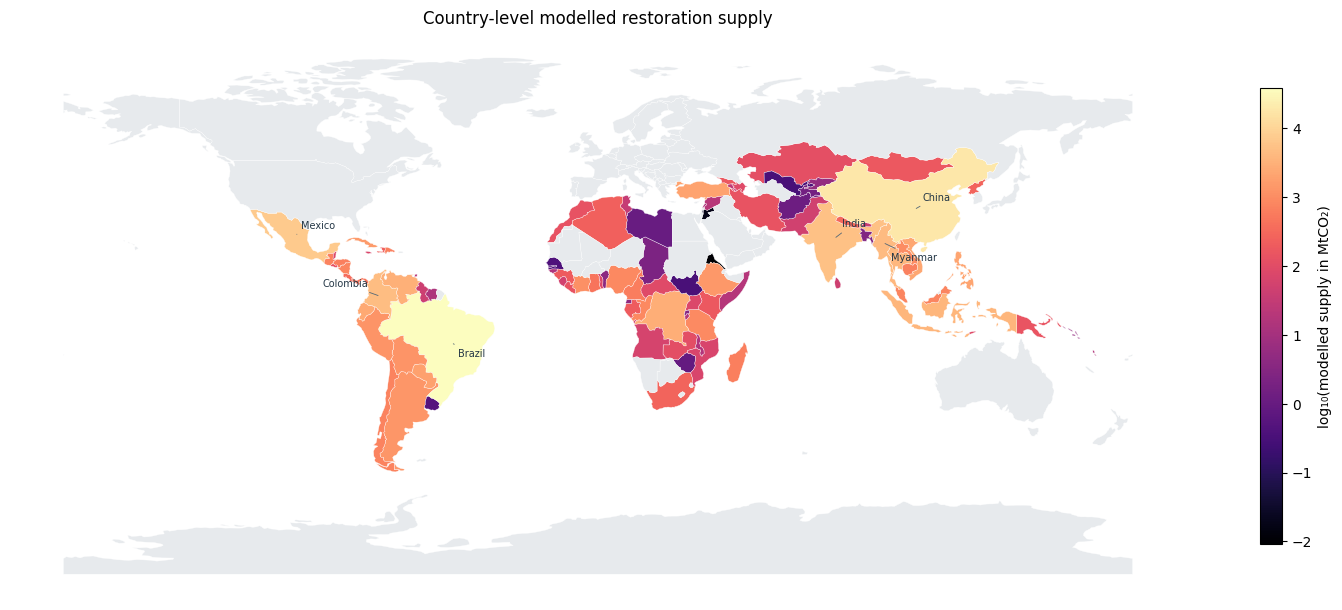

Country-level Busch calculations joined to the map: 115


In [14]:
import geopandas as gpd

boundary_path = ROOT / 'data' / 'raw' / 'geospatial' / 'boundaries' / 'ne_110m_admin_0_countries.shp'
world = gpd.read_file(boundary_path)
world['map_iso3'] = world['ISO_A3'].where(world['ISO_A3'].ne('-99'), world['ADM0_A3'])
map_values = country_finance[['iso3', 'name', 'available_supply_mtco2']].copy()
map_data = world.merge(map_values, left_on='map_iso3', right_on='iso3', how='left', validate='many_to_one')
map_data['log10_supply_mtco2'] = np.log10(map_data['available_supply_mtco2'].where(map_data['available_supply_mtco2'].gt(0)))
fig, ax = plt.subplots(figsize=(15, 7))
map_data.plot(
    column='log10_supply_mtco2',
    cmap='magma',
    linewidth=0.25,
    edgecolor='white',
    ax=ax,
    legend=True,
    missing_kwds={'color': '#E7EAED', 'edgecolor': 'white', 'label': 'No positive supply joined'},
    legend_kwds={'label': 'log₁₀(modelled supply in MtCO₂)', 'shrink': 0.68},
)
map_labels = map_data.nlargest(6, 'available_supply_mtco2')
label_offsets = {'BRA': (5, -10), 'CHN': (6, 7), 'MEX': (5, 5), 'IND': (6, 9), 'COL': (-42, 7), 'MMR': (6, -13)}
for row in map_labels.itertuples(index=False):
    if pd.notna(row.LABEL_X) and pd.notna(row.LABEL_Y):
        short_name = str(row.name).split(' (')[0]
        ax.annotate(
            short_name,
            (row.LABEL_X, row.LABEL_Y),
            xytext=label_offsets.get(row.iso3, (5, 5)),
            textcoords='offset points',
            fontsize=7,
            color='#243746',
            arrowprops={'arrowstyle': '-', 'color': '#526777', 'linewidth': 0.6},
        )
ax.set_title('Country-level modelled restoration supply')
ax.set_axis_off()
fig.tight_layout()
plt.show()
print(f'Country-level Busch calculations joined to the map: {map_data["iso3"].nunique()}')

## 4. Compare the natural-regeneration soil scenarios

The reference calculation and two soil-rate alternatives are each recalculated for every country dataset in the Busch archive. Only after those calculations does a second table join the resulting scenarios to positive FRA-loss targets. The plantation soil rate stays fixed. These are deterministic sensitivity scenarios, not confidence intervals.

,soil_scenario,nr_soil_rate_tC_ha_yr,country_dta_inputs,nr_cells,plantation_cells,method_switches,available_supply_discounted_tco2
0,busch_reference,0.415108,138,25159263,28648927,0,1.203847e+11
1,post_kwon_2000,0.338000,138,25018163,28790027,141100,1.193490e+11
2,zero_soil_change,0.000000,138,20584198,29884733,4575065,1.149296e+11


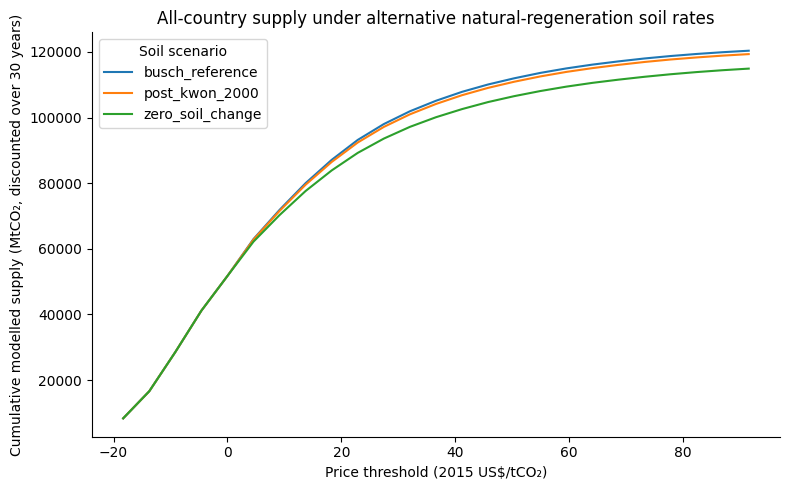

,soil_scenario,status,positive_loss_entities,reported_loss_capacity_tco2_yr
0,busch_reference,no_country_input_dta,31,2.870225e+06
1,busch_reference,target_outside_cell_supply,11,2.578429e+06
2,busch_reference,target_within_cell_supply,58,2.792875e+07
3,post_kwon_2000,no_country_input_dta,31,2.870225e+06
4,post_kwon_2000,target_outside_cell_supply,11,2.578429e+06
5,post_kwon_2000,target_within_cell_supply,58,2.792875e+07
6,zero_soil_change,no_country_input_dta,31,2.870225e+06
7,zero_soil_change,target_outside_cell_supply,12,2.602172e+06
8,zero_soil_change,target_within_cell_supply,57,2.790500e+07


In [15]:
soil_sensitivity_path = BUSCH_DIR / f"{busch_prefix}_soil_sensitivity_country.csv"
sensitivity_curves_path = BUSCH_DIR / f"{busch_prefix}_soil_sensitivity_price_curves.csv"
sensitivity_coverage_path = BUSCH_DIR / f"{busch_prefix}_soil_sensitivity_coverage.csv"

soil_sensitivity = pd.read_csv(soil_sensitivity_path)
sensitivity_summary = (
    soil_sensitivity.groupby("soil_scenario", dropna=False)
    .agg(
        nr_soil_rate_tC_ha_yr=("nr_soil_rate_tC_ha_yr", "first"),
        country_dta_inputs=("iso3", "nunique"),
        nr_cells=("natural_regeneration_cells_selected", "sum"),
        plantation_cells=("plantation_cells_selected", "sum"),
        method_switches=("method_switches_vs_reference", "sum"),
        available_supply_discounted_tco2=("available_discounted_tco2", "sum"),
    )
    .reset_index()
)
display(sensitivity_summary)

sensitivity_curves = pd.read_csv(sensitivity_curves_path)
global_sensitivity_curves = (
    sensitivity_curves.groupby(["soil_scenario", "price_usd2015_per_tco2"], as_index=False)
    ["cumulative_supply_discounted_tco2"].sum()
)
fig, ax = plt.subplots(figsize=(8, 5))
for scenario, rows in global_sensitivity_curves.groupby("soil_scenario"):
    rows = rows.sort_values("price_usd2015_per_tco2")
    ax.plot(
        rows["price_usd2015_per_tco2"],
        rows["cumulative_supply_discounted_tco2"] / 1e6,
        label=scenario,
    )
ax.set_xlabel("Price threshold (2015 US$/tCO₂)")
ax.set_ylabel("Cumulative modelled supply (MtCO₂, discounted over 30 years)")
ax.set_title("All-country supply under alternative natural-regeneration soil rates")
ax.legend(title="Soil scenario")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

soil_sensitivity_coverage = pd.read_csv(sensitivity_coverage_path)
target_sensitivity_summary = (
    soil_sensitivity_coverage.groupby(["soil_scenario", "status"], dropna=False)
    .agg(
        positive_loss_entities=("iso3", "nunique"),
        reported_loss_capacity_tco2_yr=("reported_loss_capacity_tco2_yr", "sum"),
    )
    .reset_index()
)
display(target_sensitivity_summary)

### Country-level soil-rate sensitivity

For each country in the Busch dataset, compare modelled supply under the two alternative natural-regeneration soil rates with the Busch-reference scenario. The box plot shows the country-by-country change in total discounted supply; the bar chart displays country counts of method switches relative to the reference. Plantation soil rates remain fixed in all scenarios.

,soil_scenario,countries,median_change_mtco2,q05_change_mtco2,q95_change_mtco2,countries_supply_increased,countries_supply_decreased
0,zero_soil_change,138,-0.811478,-181.316453,0.0,0,101
1,post_kwon_2000,138,-0.164266,-33.841714,0.0,0,101


C:\Users\aurel\AppData\Local\Temp\ipykernel_21788\3421379345.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  soil_change_boxes = ax.boxplot(


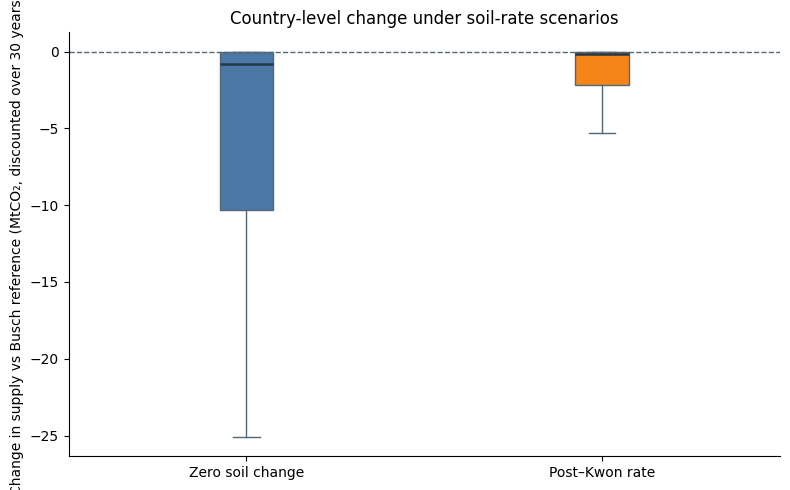

In [16]:
reference_supply = (
    soil_sensitivity.loc[soil_sensitivity['soil_scenario'].eq('busch_reference')]
    .set_index('iso3')['available_discounted_tco2']
)
scenario_names = ['zero_soil_change', 'post_kwon_2000']
scenario_changes = {}
for scenario in scenario_names:
    current = soil_sensitivity.loc[soil_sensitivity['soil_scenario'].eq(scenario)].set_index('iso3')['available_discounted_tco2']
    scenario_changes[scenario] = (current - reference_supply).dropna() / 1e6

change_summary = pd.DataFrame([
    {
        'soil_scenario': scenario,
        'countries': values.size,
        'median_change_mtco2': values.median(),
        'q05_change_mtco2': values.quantile(0.05),
        'q95_change_mtco2': values.quantile(0.95),
        'countries_supply_increased': int(values.gt(0).sum()),
        'countries_supply_decreased': int(values.lt(0).sum()),
    }
    for scenario, values in scenario_changes.items()
])
display(change_summary)

fig, ax = plt.subplots(figsize=(8, 5))
soil_change_boxes = ax.boxplot(
    [scenario_changes[name].to_numpy() for name in scenario_names],
    labels=['Zero soil change', 'Post–Kwon rate'],
    showfliers=False,
    patch_artist=True,
    boxprops={'facecolor': '#DCEBE1', 'edgecolor': '#526777'},
    medianprops={'color': '#243746', 'linewidth': 1.8},
    whiskerprops={'color': '#526777'},
    capprops={'color': '#526777'},
)
for box, color in zip(soil_change_boxes['boxes'], ['#4C78A8', '#F58518']):
    box.set_facecolor(color)
ax.axhline(0, color='#526777', linewidth=1, linestyle='--')
ax.set_ylabel('Change in supply vs Busch reference (MtCO₂, discounted over 30 years)')
ax.set_title('Country-level change under soil-rate scenarios')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

#### Countries with the most method switches

The grouped bars list the countries with the highest number of cell-level method changes under either alternative soil scenario. Counts are relative to the Busch-reference run.

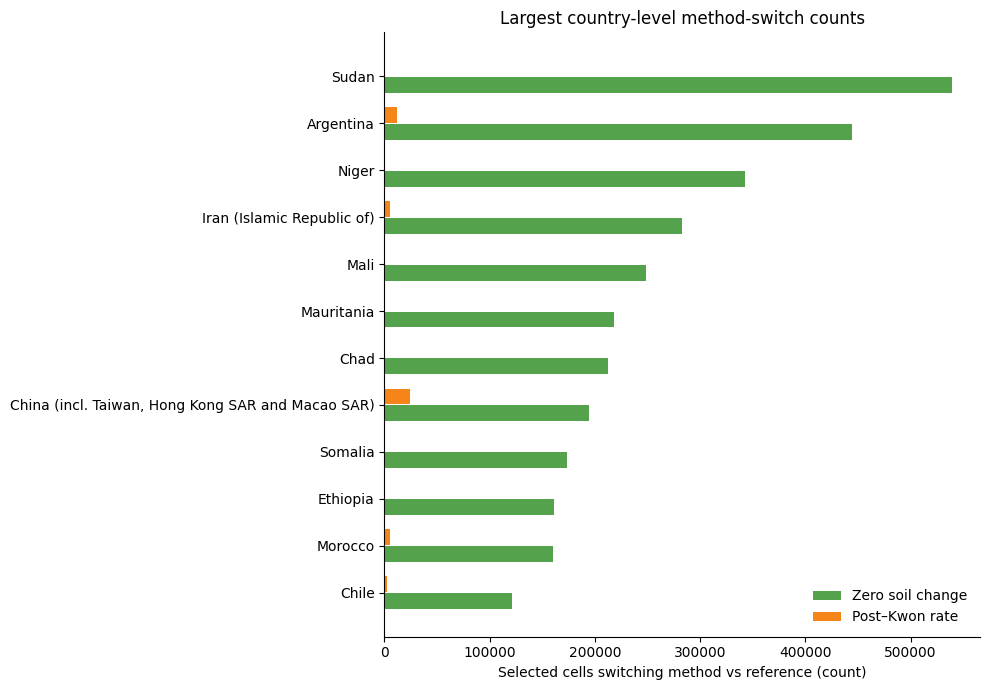

In [17]:
switch_data = soil_sensitivity.loc[
    soil_sensitivity['soil_scenario'].isin(scenario_names),
    ['iso3', 'soil_scenario', 'method_switches_vs_reference'],
].copy()
switch_wide = switch_data.pivot(index='iso3', columns='soil_scenario', values='method_switches_vs_reference').fillna(0)
switch_wide['max_switches'] = switch_wide[scenario_names].max(axis=1)
top_switch_iso3 = switch_wide.nlargest(12, 'max_switches').index
switch_long = (
    switch_wide.loc[top_switch_iso3, scenario_names]
    .reset_index()
    .melt(id_vars='iso3', var_name='soil_scenario', value_name='cells_switched')
    .merge(country_metadata[['iso3', 'name']], on='iso3', how='left', validate='many_to_one')
)
switch_long['display_name'] = switch_long['name'].fillna(switch_long['iso3'])
labels = switch_wide.loc[top_switch_iso3].index.to_series().map(
    country_metadata.set_index('iso3')['name']
).fillna(switch_wide.loc[top_switch_iso3].index.to_series())
labels = labels.iloc[::-1]
zero_values = switch_wide.loc[top_switch_iso3, 'zero_soil_change'].to_numpy()[::-1]
post_values = switch_wide.loc[top_switch_iso3, 'post_kwon_2000'].to_numpy()[::-1]
y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(y - 0.18, zero_values, height=0.34, color='#54A24B', label='Zero soil change')
ax.barh(y + 0.18, post_values, height=0.34, color='#F58518', label='Post–Kwon rate')
ax.set_yticks(y, labels)
ax.set_xlabel('Selected cells switching method vs reference (count)')
ax.set_title('Largest country-level method-switch counts')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 5. Read the target-cost results alongside the 2% allocation

The all-country files show the modelled costs and supply for every archive input. Target-cost fields appear in the separate positive-loss coverage table only after the ISO3 join. The 2% GCW allocation remains an annual hypothetical amount in 2015 US dollars; target costs are derived from the 30-year restoration calculation. Their comparison is a scenario comparison, not an observed budget or financing gap.

In [18]:
comparison_path = VALIDATION / "finance_action_cost_comparison.json"
if comparison_path.exists():
    comparison = json.loads(comparison_path.read_text(encoding="utf-8"))
    comparison["restoration_calculation"] = (
        "All country-level datasets in the Busch archive are calculated "
        "before matching positive FRA-loss targets."
    )
    status_labels = {
        "target_within_cell_supply": "Target within modelled supply",
        "no_country_input_dta": "No matching country-level calculation",
        "target_outside_cell_supply": "Target exceeds modelled cell supply",
    }
    comparison["restoration_join_status_counts"] = {
        status_labels.get(status, status): count
        for status, count in comparison["restoration_join_status_counts"].items()
    }
    display(pd.Series(comparison, name="value").to_frame())
else:
    print("The finance comparison summary is not present yet.")

print(
    "All-country Busch dataset processing complete:",
    busch_summary["processing_scope_complete"],
    "| published country-curve comparison performed:",
    busch_summary["published_curve_comparison_performed"],
)

,value
gcw_usd2015_yr,8261443009142.151367
our_allocation_rate,0.02
our_2pct_gcw_allocation_usd2015_yr,165228860182.843018
positive_loss_entities,100
positive_loss_capacity_tco2_yr,33377399.801651
source_discount_factor_30yr,15.707225
restoration_calculation,All country-level datasets in the Busch archiv...
published_country_curve_comparison_performed,False
restoration_join_status_counts,"{'Target within modelled supply': 58, 'No matc..."


All-country Busch dataset processing complete: True | published country-curve comparison performed: False
